# Wadi Ghadir ground magnetic survey – step-by-step processing

**Wadi Ghadir, Eastern Desert, Egypt · total-field ground magnetics · January 2026**

**Prepared by Dr. Mohamed Sobh, LIAG** (Leibniz Institute for Applied Geophysics)

This notebook processes the magnetic data from the supplied workbook to the reduced-to-pole map. Each step
loads or processes the data, shows the result as tables and plots, and has parameters you can adapt.

| Step | Content |
|---:|---|
| 1 | Load the data, coordinates and survey days |
| 2 | Diurnal correction (as supplied) |
| 3 | Despiking |
| 4 | IGRF-14 main field and total-field anomaly |
| 5 | Quality statistics: days and crossovers |
| 6 | Gridding |
| 7 | Reduction to the pole |
| 8 | Publication maps and export |

**Assumption:** the file has times but no dates, so the IGRF is evaluated for 20 January 2026. Change
`SURVEY_DATE` in step 4 if the real dates are known. The secular variation is about 27 nT per year, a
near-constant shift that does not change the anomaly pattern.


**How to use this notebook**

* Run the cells from top to bottom (*Run → Run All Cells*), or one step at a time with *Shift + Enter*.
* Every step has up to three cells:
  * **✏️ PARAMETERS**: values you may change, such as thresholds, densities or grid spacing.
  * **▶ PROCESSING**: calls the processing functions of the `wghadir` package.
  * **📊 RESULT**: tables and plots of the result of that step.
* After changing a parameter, re-run that step **and all steps below it**, because each step uses the
  results of the previous ones.
* To change *how* a step works, open the function named in its processing cell, e.g. `qc.row_qc` in
  `wghadir/gravity/qc.py`.
* The default parameters reproduce the delivered results exactly.

## 0  Set-up

In [1]:
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"bbox_inches": "tight", "pil_kwargs": {"quality": 82}}
import json
import os
import sys
import warnings

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# make the wghadir package importable (repository layout: this notebook is in notebooks/)
REPO = ".." if os.path.basename(os.getcwd()) == "notebooks" else "."
if os.path.abspath(REPO) not in sys.path:
    sys.path.insert(0, os.path.abspath(REPO))
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)

import datetime as dt

from wghadir.chains.magnetic import DEFAULT_BASE_100
from wghadir.common import geodata, mapping
from wghadir.gravity import settings as gravity_settings
from wghadir.magnetic import export, processing, settings
from wghadir.magnetic import maps as mmaps

# ✏️ input and output
MAG_FILE = os.path.join(REPO, "data", "raw", "magnetics", "All_Data_Corrected_Total_Intensity.xlsx")
EXTERNAL_DIR = os.path.join(REPO, "data", "external")      # DEM for the relief (from the gravity notebook)
OUT_DIR = os.path.join(REPO, "outputs")
for sub in ("magnetics", "grids", "tables", "deliverables"):
    os.makedirs(os.path.join(OUT_DIR, sub), exist_ok=True)

# base 100 as map symbol (from the gravity results if available)
summary_file = os.path.join(OUT_DIR, "summary.json")
ref = json.load(open(summary_file))["ref"] if os.path.exists(summary_file) else {"base_100": DEFAULT_BASE_100}
dem = geodata.Grid(geodata.fetch_dem(gravity_settings.DEM_BOUNDS,
                                     os.path.join(EXTERNAL_DIR, gravity_settings.DEM_FILE)))
basemap = mapping.Basemap(dem)
DAY_COLORS = plt.cm.tab10
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
print("ready")

ready


## 1  Load the data

`processing.load` reads every row of the workbook and keeps its Excel row number. It computes UTM 36N coordinates
from latitude/longitude and compares them with the supplied x/y. Survey days are identified where the time steps
back by more than 30 minutes (`day_seq`). Rows without time or position are flagged `NON_DATA_ROW`.

In [2]:
# ▶ PROCESSING
data = processing.load(MAG_FILE)
print(f"{len(data)} rows; median difference recomputed vs supplied UTM: {np.nanmedian(data['utm_check_m']):.2f} m")
display(data[["source_row", "day_seq", "time_hhmmss", "lat", "lon", "elev_file", "reading_nT", "tmi_corr_nT"]].head())
data[data["day_seq"] > 0].groupby("day_seq").agg(readings=("source_row", "size"),
                                                 first=("time_hhmmss", "first"), last=("time_hhmmss", "last"))

12163 rows; median difference recomputed vs supplied UTM: 0.01 m


,source_row,day_seq,time_hhmmss,lat,lon,elev_file,reading_nT,tmi_corr_nT
0,2,1,114913.0,24.778880,34.859040,234.40,42096.89,42085.89
1,3,1,115007.0,24.778883,34.859037,235.28,42097.14,42086.14
2,4,1,115022.0,24.778883,34.859035,235.65,42097.34,42086.34
3,5,1,115155.0,24.778999,34.859124,235.32,42098.00,42087.00
4,6,1,123025.0,24.780081,34.858329,240.78,42098.17,42091.17


,readings,first,last
day_seq,,,
1,52,114913.0,133037.0
2,1463,93713.0,140032.0
3,1322,65249.0,140820.0
4,158,101452.0,140016.0
5,5199,71234.0,132402.0
6,1897,83431.0,142316.0
7,330,80252.0,145116.0
8,1453,72958.0,144310.0
9,241,75825.0,145122.0


Text(0.0, 1.0, 'Survey tracks by day')

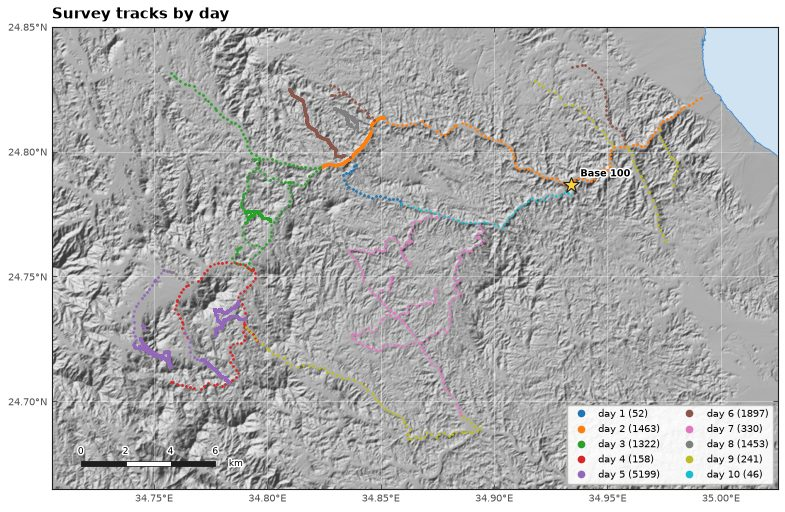

In [3]:
# 📊 RESULT
mapping.apply_map_style()
plt.rcParams.update({"figure.dpi": 100})
d = data[data["day_seq"] > 0]
fig, ax = plt.subplots(figsize=(11, 6))
basemap.draw(ax, relief_alpha=0.85)
for k, dd in d.groupby("day_seq"):
    ax.plot(dd["lon"], dd["lat"], ".", ms=1.5, color=DAY_COLORS((k - 1) % 10), label=f"day {k} ({len(dd)})", zorder=10)
mapping.base100(ax, ref)
mapping.scalebar(ax)
ax.legend(loc="lower right", markerscale=6, fontsize=7, ncol=2)
ax.set_title("Survey tracks by day", loc="left")

## 2  Diurnal correction (as supplied)

The workbook contains the raw reading and the diurnally corrected total field, so the applied correction is
`diurnal_corr_nT = corrected − reading`. The plot shows it against time for every day, as a check of the
supplied correction; choose `SHOW_DAY` for the profile below.

In [4]:
# ✏️ PARAMETERS – edit and re-run from here
SHOW_DAY = 5

In [5]:
# ▶ PROCESSING
d = data[data["day_seq"] > 0]
d.groupby("day_seq")["diurnal_corr_nT"].describe().round(1)

,count,mean,std,min,25%,50%,75%,max
day_seq,,,,,,,,
1,52.0,-7.3,13.9,-104.0,-7.0,-5.0,-4.8,0.0
2,1463.0,-6.7,2.0,-9.0,-8.0,-8.0,-6.0,-0.2
3,1322.0,-30.7,10.9,-36.0,-36.0,-35.0,-34.0,-0.5
4,158.0,-33.7,34.5,-80.0,-80.0,-15.0,-3.0,-2.0
5,5199.0,-94.8,52.8,-170.0,-150.0,-91.0,-50.0,-3.0
6,1897.0,-17.3,8.3,-80.0,-25.0,-19.0,-10.0,-5.0
7,330.0,-6.0,3.5,-12.0,-11.0,-4.0,-4.0,-2.0
8,1453.0,-33.2,8.6,-44.0,-44.0,-33.0,-30.0,-3.0
9,241.0,-14.1,2.9,-21.0,-17.0,-12.0,-12.0,-10.0


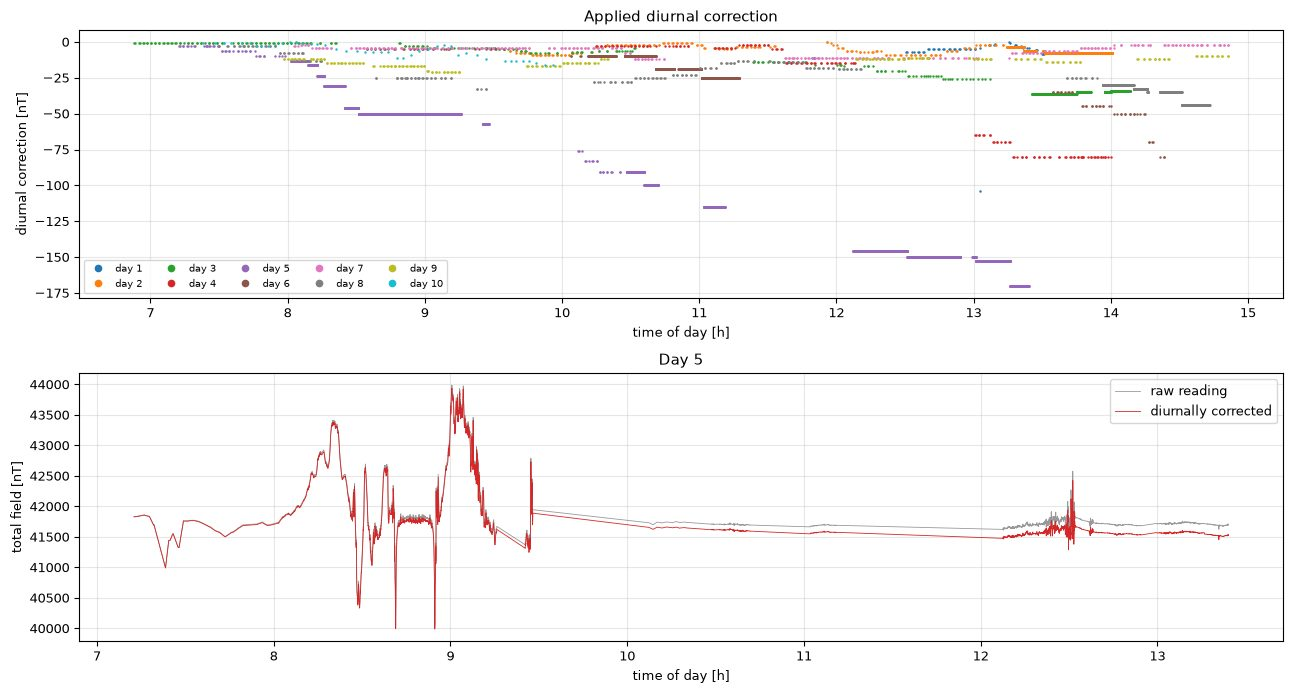

In [6]:
# 📊 RESULT
plt.rcdefaults()
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3, "font.size": 9})
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
for k, dd in d.groupby("day_seq"):
    axes[0].plot(dd["time_s"] / 3600, dd["diurnal_corr_nT"], ".", ms=1.5, color=DAY_COLORS((k - 1) % 10), label=f"day {k}")
axes[0].set(xlabel="time of day [h]", ylabel="diurnal correction [nT]", title="Applied diurnal correction")
axes[0].legend(ncol=5, markerscale=6, fontsize=7)
dd = d[d["day_seq"] == SHOW_DAY]
axes[1].plot(dd["time_s"] / 3600, dd["reading_nT"], "-", lw=0.6, color="0.6", label="raw reading")
axes[1].plot(dd["time_s"] / 3600, dd["tmi_corr_nT"], "-", lw=0.6, color="C3", label="diurnally corrected")
axes[1].set(xlabel="time of day [h]", ylabel="total field [nT]", title=f"Day {SHOW_DAY}")
axes[1].legend()
plt.tight_layout()

## 3  Despiking

`processing.despike` runs a Hampel filter along the readings of each day. A reading is a spike if it deviates from
the running median of `window` readings by more than max(`floor_nt`, `k` × 1.4826 × MAD). Spikes are flagged
(`SPIKE_HAMPEL`) and excluded from gridding, but kept in the table.

**Try it:** set `k = 4` or `floor_nt = 15` and look at the plot.

In [7]:
# ✏️ PARAMETERS – edit and re-run from here
HAMPEL = dict(window=settings.HAMPEL_WINDOW,       # 11 readings (~28 m)
              k=settings.HAMPEL_K,                 # 6
              floor_nt=settings.HAMPEL_FLOOR_NT)   # 30 nT
SHOW_DAY = 5

In [8]:
# ▶ PROCESSING
data = processing.despike(data, **HAMPEL)
spikes = data["flags"].str.contains("SPIKE")
print(f"{spikes.sum()} spikes rejected, {data['accepted'].sum()} readings accepted")
data[spikes].groupby("day_seq").size().rename("spikes").to_frame().T

155 spikes rejected, 12006 readings accepted


day_seq,1,2,3,4,5,6,7,8,9,10
spikes,1,4,5,10,90,8,5,13,15,4


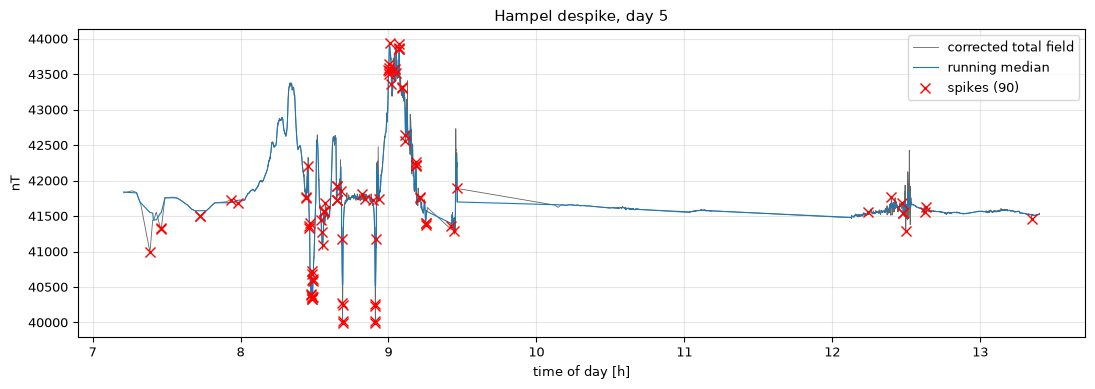

In [9]:
# 📊 RESULT
dd = data[data["day_seq"] == SHOW_DAY]
sp = dd[dd["flags"].str.contains("SPIKE")]
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(dd["time_s"] / 3600, dd["tmi_corr_nT"], "-", lw=0.6, color="0.4", label="corrected total field")
ax.plot(dd["time_s"] / 3600, dd["hampel_median_nT"], "-", lw=0.8, color="C0", label="running median")
ax.plot(sp["time_s"] / 3600, sp["tmi_corr_nT"], "rx", ms=7, label=f"spikes ({len(sp)})")
ax.set(xlabel="time of day [h]", ylabel="nT", title=f"Hampel despike, day {SHOW_DAY}")
ax.legend()

## 4  IGRF-14 main field and total-field anomaly

`processing.add_igrf` computes the IGRF-14 field (ppigrf) at every reading position and elevation: total field F,
inclination I and declination D. The total-field anomaly is **TMA = TMI − F(IGRF)**. The field direction (I, D)
is used for the reduction to the pole in step 7.

In [10]:
# ✏️ PARAMETERS – edit and re-run from here
SURVEY_DATE = settings.SURVEY_DATE     # ASSUMED 2026-01-20 – e.g. dt.datetime(2026, 1, 18)

In [11]:
# ▶ PROCESSING
data = processing.add_igrf(data, SURVEY_DATE)
acc = data[data["accepted"]]
INC, DEC = float(acc["igrf_inc_deg"].median()), float(acc["igrf_dec_deg"].median())
print(f"IGRF-14 for {SURVEY_DATE:%Y-%m-%d}: F = {acc['igrf_F_nT'].median():.1f} nT, I = {INC:.2f}°, D = {DEC:.2f}°")
acc[["tmi_corr_nT", "igrf_F_nT", "tma_nT"]].describe().round(1)

IGRF-14 for 2026-01-20: F = 41971.2 nT, I = 36.74°, D = 4.22°


,tmi_corr_nT,igrf_F_nT,tma_nT
count,12006.0,12006.0,12006.0
mean,41882.8,41967.6,-84.8
std,354.7,24.5,353.9
min,40393.2,41932.1,-1543.5
25%,41634.4,41942.7,-313.1
50%,41882.0,41971.2,-94.4
75%,41934.3,41992.3,-51.5
max,43935.9,42023.9,1998.9


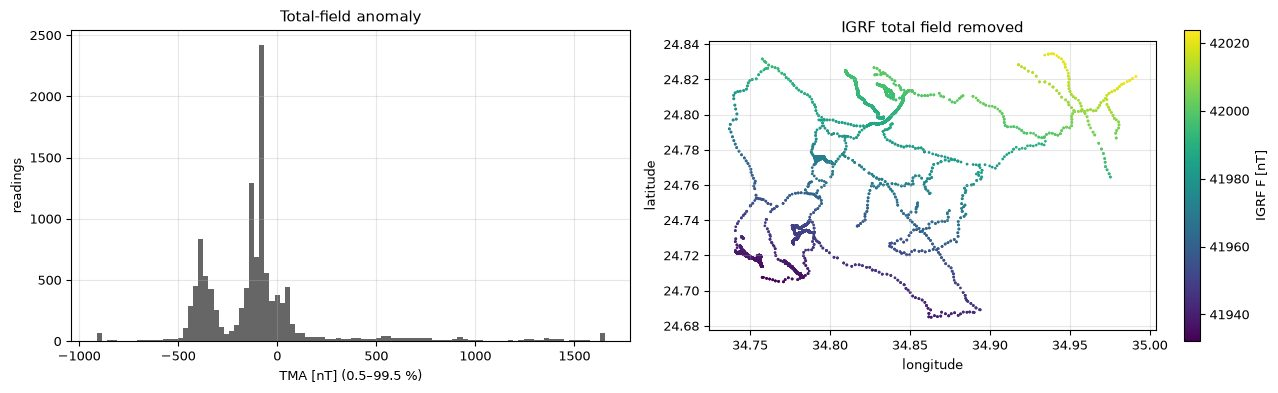

In [12]:
# 📊 RESULT
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].hist(acc["tma_nT"].clip(*np.percentile(acc["tma_nT"], [0.5, 99.5])), bins=100, color="0.4")
axes[0].set(xlabel="TMA [nT] (0.5–99.5 %)", ylabel="readings", title="Total-field anomaly")
sc = axes[1].scatter(acc["lon"], acc["lat"], c=acc["igrf_F_nT"], s=1, cmap="viridis")
plt.colorbar(sc, ax=axes[1], label="IGRF F [nT]")
axes[1].set(xlabel="longitude", ylabel="latitude", title="IGRF total field removed", aspect=1 / np.cos(np.radians(24.76)))
plt.tight_layout()

## 5  Quality statistics: days and crossovers

`processing.day_summary` gives per-day statistics. `processing.crossovers` compares accepted readings less than
`CROSSOVER_M` apart that were measured on different days, which shows any level differences between days.
`processing.igrf_date_sensitivity` shows how much the IGRF changes with the assumed date.

In [13]:
# ✏️ PARAMETERS – edit and re-run from here
CROSSOVER_M = settings.CROSSOVER_M     # 5 m

In [14]:
# ▶ PROCESSING
days = processing.day_summary(data)
crossover_pairs, crossovers = processing.crossovers(data, maxdist=CROSSOVER_M)
igrf_sensitivity = processing.igrf_date_sensitivity(float(acc["lon"].median()), float(acc["lat"].median()))
display(days.round(1))
display(crossovers.round(1))
igrf_sensitivity.round(2)

,day_seq,n_readings,n_accepted,time_first,time_last,lon_median,lat_median,diurnal_min_nT,diurnal_max_nT,tmi_median_nT,tmi_min_nT,tmi_max_nT
0,1,52,51,114913.0,133037.0,34.8,24.8,-104.0,0.0,42037.4,41889.9,42093.0
1,2,1463,1459,93713.0,140032.0,34.8,24.8,-9.0,-0.2,42015.8,41519.6,42449.0
2,3,1322,1317,65249.0,140820.0,34.8,24.8,-36.0,-0.5,41894.3,41796.0,42162.7
3,4,158,148,101452.0,140016.0,34.8,24.7,-80.0,-2.0,41832.3,41305.4,42076.2
4,5,5199,5109,71234.0,132402.0,34.8,24.7,-170.0,-3.0,41604.2,39988.7,43937.2
5,6,1897,1889,83431.0,142316.0,34.8,24.8,-80.0,-5.0,41867.3,41756.0,42175.0
6,7,330,325,80252.0,145116.0,34.9,24.7,-12.0,-2.0,41890.0,41755.0,42459.2
7,8,1453,1440,72958.0,144310.0,34.8,24.8,-44.0,-3.0,41917.9,41569.5,42296.2
8,9,241,226,75825.0,145122.0,34.9,24.7,-21.0,-10.0,41813.9,41479.4,42040.3
9,10,46,42,72302.0,95604.0,34.9,24.8,-16.0,-0.2,42105.4,41436.2,42695.0


,day_a,day_b,n_pairs,median_dTMI_nT,mad_dTMI_nT
0,1,10,3,-4.9,0.2


,date,F_nT,inc_deg,dec_deg
0,2025-01-15,41943.82,36.71,4.22
1,2025-07-15,41957.47,36.73,4.22
2,2026-01-20,41971.72,36.74,4.22
3,2026-07-15,41984.99,36.76,4.23


[Text(0.5, 0, 'TMI difference between days [nT] (clipped ±100)'),
 Text(0, 0.5, 'pairs'),
 (-100.0, 100.0),
 Text(0.5, 1.0, '3 crossover pairs, median |Δ| = 4.9 nT  (lines of different days rarely come within 5 m)')]

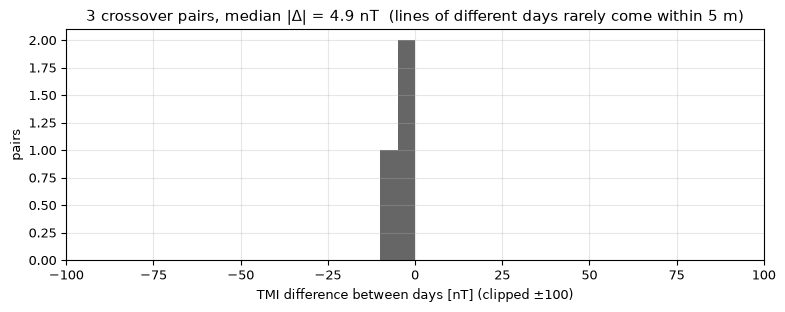

In [15]:
# 📊 RESULT
fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(crossover_pairs["dTMI_nT"].clip(-100, 100), bins=np.arange(-100, 105, 5), color="0.4")
ax.set(xlabel="TMI difference between days [nT] (clipped ±100)", ylabel="pairs", xlim=(-100, 100),
       title=f"{len(crossover_pairs)} crossover pairs, median |Δ| = {np.median(np.abs(crossover_pairs['dTMI_nT'])):.1f} nT"
             "  (lines of different days rarely come within 5 m)")

## 6  Gridding

As for the gravity: UTM 36N, block median, linear trend plus damped biharmonic spline (Verde), blanked farther
than `mask_km` from the data (`processing.grid_field`). `processing.cv_rmse` estimates the gridding error by block
cross-validation. Colours are histogram-equalised (`mmaps.equalised_norm`) so that the strong anomaly does not
compress the colour range.

In [16]:
# ✏️ PARAMETERS – edit and re-run from here
GRID = dict(spacing=settings.GRID_SPACING_M,   # 50 m grid
            block_m=settings.BLOCK_M,          # 100 m block median
            mask_km=settings.MASK_KM,          # blank > 2 km from data
            damping=settings.SPLINE_DAMPING)   # 1e-6

In [17]:
# ▶ PROCESSING
acc = data[data["accepted"]]
x, y = acc["utm_e"].values, acc["utm_n"].values
grid_tmi = processing.grid_field(x, y, acc["tmi_corr_nT"].values, **GRID)
grid_tma = processing.grid_field(x, y, acc["tma_nT"].values, **GRID)
cv = {"tmi": processing.cv_rmse(x, y, acc["tmi_corr_nT"].values, GRID["block_m"], GRID["damping"]),
      "tma": processing.cv_rmse(x, y, acc["tma_nT"].values, GRID["block_m"], GRID["damping"])}
print("grid size:", grid_tma["value"].shape, " cross-validation rms [nT]:", {k: round(v, 1) for k, v in cv.items()})

grid size: (420, 654)  cross-validation rms [nT]: {'tmi': 169.1, 'tma': 169.1}


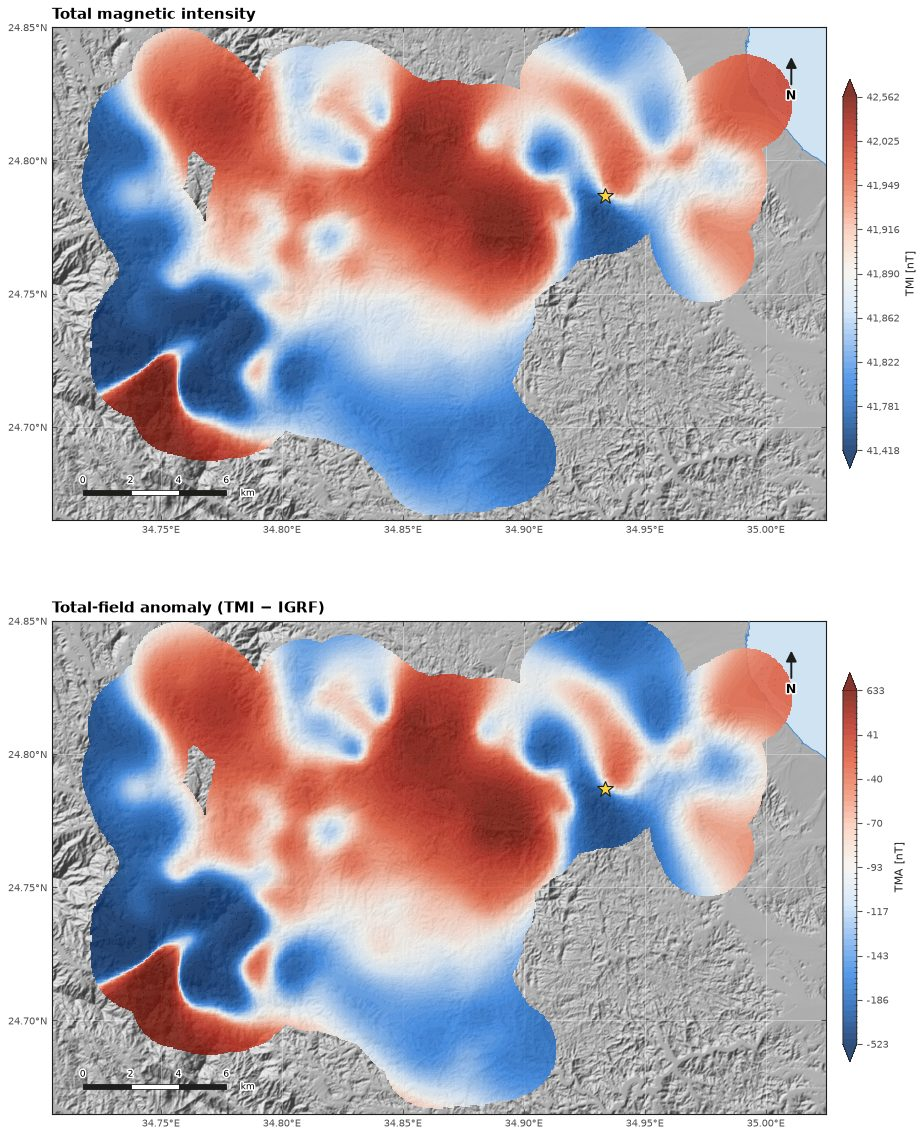

In [18]:
# 📊 RESULT
mapping.apply_map_style()
plt.rcParams.update({"figure.dpi": 100})


def magnetic_map(ax, grid, title, label):
    """Gridded magnetic map with histogram-equalised colours (edit freely)."""
    LON, LAT = processing.grid_lonlat(grid)
    Z = grid["value"].values
    norm, levels = mmaps.equalised_norm(Z)
    basemap.draw(ax, relief_alpha=0.85)
    m = ax.pcolormesh(LON, LAT, Z, cmap=mapping.ANOM, norm=norm, shading="auto", alpha=0.85, zorder=5)
    mapping.base100(ax, ref, label=False)
    mapping.scalebar(ax)
    mapping.north_arrow(ax)
    cb = mapping.colorbar(ax.figure, m, ax, label, shrink=0.7)
    idx = np.linspace(0, len(levels) - 1, 9).round().astype(int)
    cb.set_ticks(levels[idx])
    cb.set_ticklabels([f"{levels[i]:,.0f}" for i in idx])
    ax.set_title(title, loc="left")


fig, axes = plt.subplots(2, 1, figsize=(10, 12))
magnetic_map(axes[0], grid_tmi, "Total magnetic intensity", "TMI [nT]")
magnetic_map(axes[1], grid_tma, "Total-field anomaly (TMI − IGRF)", "TMA [nT]")
plt.tight_layout()

## 7  Reduction to the pole

`processing.rtp_grid` grids the TMA on an area extended by `mask_km + taper_km`. It tapers the grid to the median
beyond the data mask, pads it and reduces it to the pole in the wavenumber domain (Harmonica). This assumes
induced magnetisation along the field direction `INC`, `DEC`. With a different remanence direction, change INC and DEC.

In [19]:
# ✏️ PARAMETERS – edit and re-run from here
RTP_INC, RTP_DEC = INC, DEC        # field direction from step 4 [deg]
TAPER_KM = settings.TAPER_KM       # 3 km

In [20]:
# ▶ PROCESSING
grid_rtp = processing.rtp_grid(x, y, acc["tma_nT"].values, RTP_INC, RTP_DEC, taper_km=TAPER_KM, **GRID)
v = grid_rtp["value"]
print(f"RTP range {float(np.nanmin(v)):.0f} to {float(np.nanmax(v)):.0f} nT")

RTP range -541 to 2872 nT


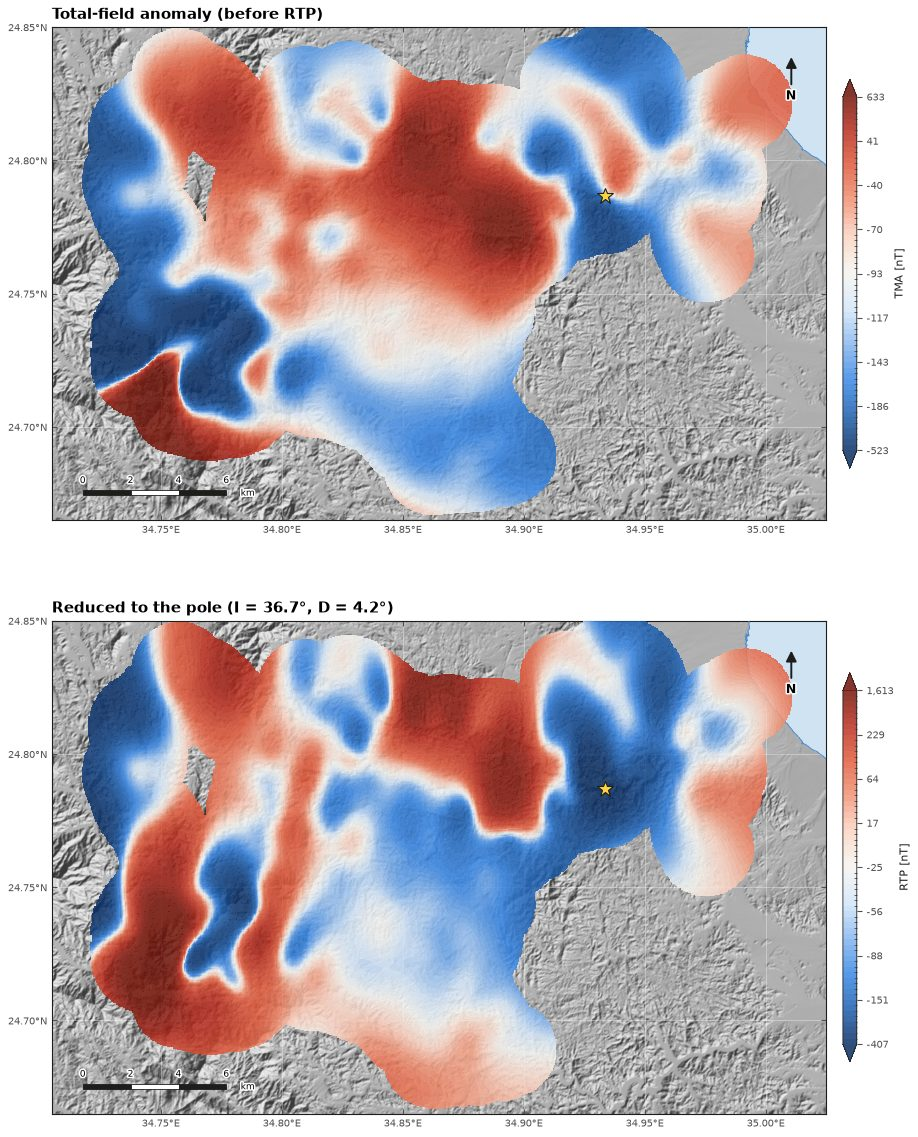

In [21]:
# 📊 RESULT
fig, axes = plt.subplots(2, 1, figsize=(10, 12))
magnetic_map(axes[0], grid_tma, "Total-field anomaly (before RTP)", "TMA [nT]")
magnetic_map(axes[1], grid_rtp, f"Reduced to the pole (I = {RTP_INC:.1f}°, D = {RTP_DEC:.1f}°)", "RTP [nT]")
plt.tight_layout()

## 8  Publication maps and export

Writes the five 400 dpi maps (`mmaps.map_points`, `mmaps.map_grid`), the grids as NetCDF and XYZ
(`mmaps.save_grid`), the QC tables, the Excel workbook (`export.write_workbook`) and `outputs/magnetics_summary.json`.

In [22]:
# ▶ PROCESSING
MAP_DIR, GRID_DIR, TABLE_DIR = (os.path.join(OUT_DIR, s) for s in ("magnetics", "grids", "tables"))
date = f"{SURVEY_DATE:%d %b %Y}"
n_acc, n_all = int(data["accepted"].sum()), int((data["day_seq"] > 0).sum())
mapping.apply_map_style()
mmaps.map_points(basemap, data, ref, "tmi_corr_nT", "Total magnetic intensity – survey readings",
                 "Total magnetic intensity [nT]", "mag01_TMI_points.png", MAP_DIR,
                 subtitle=f"{n_acc:,} accepted readings of {n_all:,}; diurnally corrected as supplied",
                 note="Points coloured by the corrected total field; ✕ = readings rejected by the Hampel despike.")
mmaps.map_points(basemap, data, ref, "tma_nT", "Total-field magnetic anomaly – survey readings", "TMI − IGRF [nT]",
                 "mag02_TMA_points.png", MAP_DIR, center=0.0,
                 subtitle=f"IGRF-14 removed for {date} (assumed date); I = {INC:.1f}°, D = {DEC:.1f}°",
                 note="Points coloured by the anomaly; ✕ = rejected spikes.")
mmaps.map_grid(basemap, grid_tmi, data, ref, "Total magnetic intensity (gridded)", "Total magnetic intensity [nT]",
               "mag03_TMI_grid.png", MAP_DIR, subtitle="Diurnally corrected total field",
               note=f"Cross-validation rms {cv['tmi']:.0f} nT.")
mmaps.map_grid(basemap, grid_tma, data, ref, "Total-field magnetic anomaly (gridded)", "TMI − IGRF [nT]",
               "mag04_TMA_grid.png", MAP_DIR, center=0.0,
               subtitle=f"IGRF-14 removed ({date}, assumed); I = {INC:.1f}°, D = {DEC:.1f}°",
               note=f"Cross-validation rms {cv['tma']:.0f} nT.")
mmaps.map_grid(basemap, grid_rtp, data, ref, "Reduced-to-pole magnetic anomaly", "RTP anomaly [nT]",
               "mag05_RTP_grid.png", MAP_DIR, center=0.0,
               subtitle=f"Induced magnetisation assumed; field I = {RTP_INC:.1f}°, D = {RTP_DEC:.1f}° (IGRF-14)",
               note="FFT RTP (Harmonica) on a padded grid tapered to the median beyond the data mask.")

for grid, name in ((grid_tmi, "tmi_nT"), (grid_tma, "tma_nT"), (grid_rtp, "rtp_nT")):
    mmaps.save_grid(grid, os.path.join(GRID_DIR, f"mag_{name.split('_')[0]}"), name)
pd.DataFrame([dict(grid=k, block_kfold_rmse_nT=v) for k, v in cv.items()]).to_csv(
    os.path.join(GRID_DIR, "mag_gridding_cross_validation.csv"), index=False)
data.to_csv(os.path.join(TABLE_DIR, "30_mag_readings_qc.csv"), index=False, float_format="%.6f")
days.to_csv(os.path.join(TABLE_DIR, "31_mag_day_summary.csv"), index=False)
crossovers.to_csv(os.path.join(TABLE_DIR, "32_mag_crossovers.csv"), index=False)
igrf_sensitivity.to_csv(os.path.join(TABLE_DIR, "33_mag_igrf_date_sensitivity.csv"), index=False)

meta = {"Source file": os.path.basename(MAG_FILE), "Rows": len(data), "Survey readings": n_all, "Accepted": n_acc,
        "Rejected spikes": int(data["flags"].str.contains("SPIKE").sum()),
        "Non-data rows": int(data["flags"].str.contains("NON_DATA").sum()),
        "Survey days (from time stamps)": int(data["day_seq"].max()),
        "IGRF model / date": f"IGRF-14, {SURVEY_DATE:%Y-%m-%d} (assumed: no dates in the file)",
        "Field inclination / declination (median)": f"{INC:.2f}° / {DEC:.2f}°",
        "Despike": f"Hampel, window {HAMPEL['window']}, k = {HAMPEL['k']}, floor {HAMPEL['floor_nt']} nT",
        "Gridding": f"{GRID['block_m']:.0f} m block median, spline, {GRID['spacing']:.0f} m grid, mask {GRID['mask_km']} km",
        "Cross-validation rms (TMI / TMA)": f"{cv['tmi']:.1f} / {cv['tma']:.1f} nT"}
export.write_workbook(os.path.join(OUT_DIR, "deliverables", "Wadi_Ghadir_Magnetic_Results.xlsx"), data, days,
                      crossovers, igrf_sensitivity, meta)
summary = dict(meta, inc=INC, dec=DEC, crossover_pairs=int(len(crossover_pairs)),
               crossover_median_abs_nT=float(np.median(np.abs(crossover_pairs["dTMI_nT"]))) if len(crossover_pairs) else None,
               tma_percentiles=np.percentile(acc["tma_nT"], [1, 50, 99]).tolist(),
               rtp_range=[float(np.nanmin(grid_rtp["value"])), float(np.nanmax(grid_rtp["value"]))])
with open(os.path.join(OUT_DIR, "magnetics_summary.json"), "w") as fh:
    json.dump(summary, fh, indent=2, default=str)
print("written:", sorted(os.listdir(MAP_DIR)))

written: ['mag01_TMI_points.png', 'mag02_TMA_points.png', 'mag03_TMI_grid.png', 'mag04_TMA_grid.png', 'mag05_RTP_grid.png']


`mag05_RTP_grid.png`

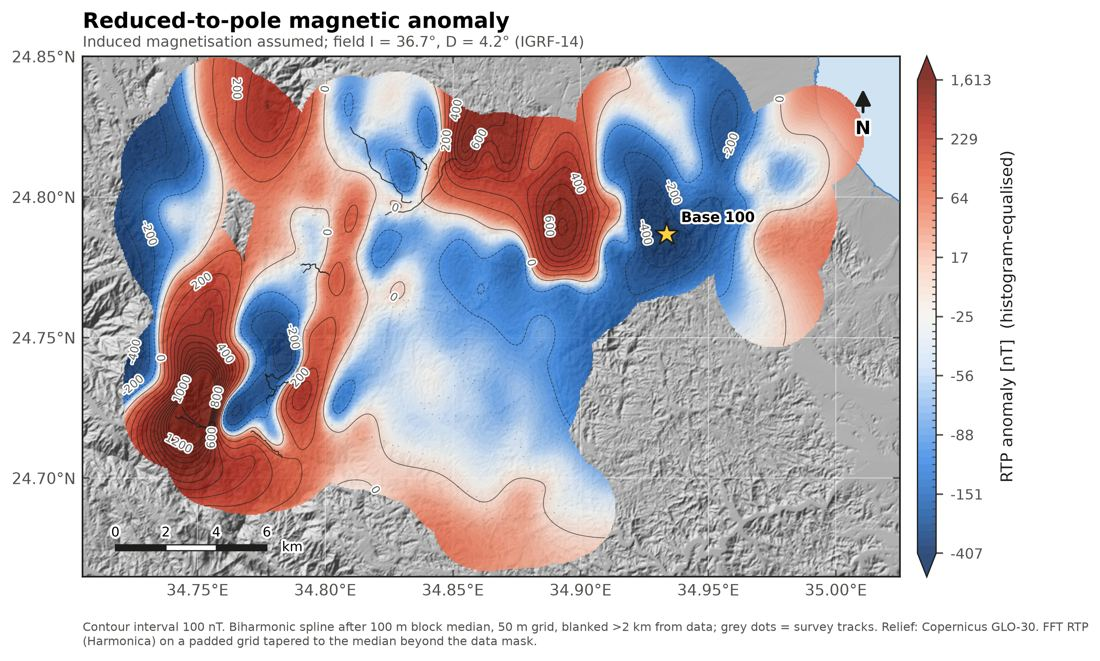

In [23]:
# 📊 RESULT
from wghadir.common.display import show_figure
show_figure(os.path.join(MAP_DIR, "mag05_RTP_grid.png"))

---
**Results:** `outputs/deliverables/Wadi_Ghadir_Magnetic_Results.xlsx`, `outputs/magnetics/` (maps),
`outputs/grids/mag_*` (NetCDF and XYZ), `outputs/tables/30–33`, `outputs/magnetics_summary.json`.

*Prepared by Dr. Mohamed Sobh, LIAG.*